# Задание 2.9*

[Небольшое научное исследование]

**а)** Прочитайте в Wikipedia статью «Множество Жюлиа»

**б)** и реализацию на *Python*.

**в)** Напишите программу с использованием инструментария *Jupyter Notebook* генерирования множества Жюлиа $f_c(z)=z^2+c$ для $c=-0{,}1+0{,}65i$ и $c=0{,}28+0{,}009i$.

**г)** Напишите программу на *Python* генерирования множеств Жюлиа для

$$
f(z)=\frac{iz^5-1}{z^5-i}\qquad\text{и}\qquad f(z)=\frac{z^2+i}{1-z^2}.
$$

## Теория

**Множество Жюлиа.** Пусть $f$ — рациональная функция. Рассмотрим орбиту точки: $z_0=z,\ z_{n+1}=f(z_n)$. Плоскость (точнее, сфера Римана $\overline{\mathbb C}$) делится на две части:

- **множество Фату** $F(f)$ — точки, вблизи которых итерации ведут себя устойчиво (близкие точки имеют похожие орбиты);
- **множество Жюлиа** $J(f)$ — его дополнение: сколь угодно малое изменение начальной точки меняет поведение орбиты («хаос»).

Ключевой факт: $J(f)$ является **границей области притяжения любого притягивающего цикла**. Поэтому чтобы увидеть $J(f)$, достаточно раскрасить плоскость по тому, как быстро точки попадают в окрестность какого-нибудь притягивающего цикла.

**Квадратичное отображение $f_c(z)=z^2+c$.** Точка $\infty$ — сверхпритягивающая неподвижная точка. *Заполненное множество Жюлиа* $K_c$ — точки с ограниченной орбитой, а $J_c=\partial K_c$. Если $|z_n|>\max(2,|c|)$, то орбита уходит в бесконечность, поэтому работает **алгоритм времени убегания**:

1. каждому пикселю сопоставляем точку $z$;
2. итерируем $z\mapsto f(z)$, пока $|z|\le R$ (у нас $R=10$) и число итераций меньше $N_{\max}$;
3. цвет пикселя — доля выполненных итераций $n/N_{\max}$.

**Связность (дихотомия Фату — Жюлиа).** $J_c$ связно, если орбита критической точки $z=0$ ограничена (то есть $c$ лежит в множестве Мандельброта), и является канторовой «пылью», если эта орбита уходит в бесконечность. Программа проверяет это для обоих значений $c$:

- $c=-0{,}1+0{,}65i$ лежит в узкой щели между главной кардиоидой и «почкой» периода 3 множества Мандельброта, чуть **вне** его: орбита нуля убегает. Значит, $J_c$ — «пыль», хотя и похожая на «кролика Дуади». Неподвижная точка $\alpha=\frac{1-\sqrt{1-4c}}{2}$ здесь почти нейтральна ($|f'(\alpha)|=|2\alpha|\approx1{,}001$), поэтому точки рядом с ней и её прообразами убегают очень медленно — это светлые «пятна» в центрах спиралей;
- $c=0{,}28+0{,}009i$ лежит чуть правее острия кардиоиды ($c=\tfrac14$), тоже вне множества Мандельброта: $J_c$ — канторова «пыль» с характерными спиралями.

**Рациональные отображения из пункта г).** Тот же алгоритм работает, потому что в обоих случаях $\infty$ входит в сверхпритягивающий цикл периода 2:

- $f(z)=\dfrac{iz^5-1}{z^5-i}$: $\ \infty\mapsto i\mapsto\infty$ и $0\mapsto -i\mapsto 0$ — два сверхпритягивающих 2-цикла. Точки первого бассейна «убегают» за окружность $|z|=R$, точки второго — никогда; граница между двумя цветами и есть множество Жюлиа;
- $f(z)=\dfrac{z^2+i}{1-z^2}$: $\ \infty\mapsto-1\mapsto\infty$ — сверхпритягивающий 2-цикл; цвет показывает, за сколько шагов точка попадает в его бассейн, чёрным закрашены точки, которые в него не попадают.

**Реализация.** В образце из условия используется двойной цикл по пикселям на чистом Python (очень медленно). Здесь итерации выполняются сразу над всем массивом точек `numpy`, причём на каждом шаге обрабатываются только ещё не «убежавшие» точки. Критерий остановки и радиус убегания $R=10$ — те же, что в образце; для квадратичных отображений взято окно $[-1{,}5;\,1{,}5]^2$, для рациональных — $[-2{,}1;\,2{,}1]^2$. Оси направлены стандартно ($\operatorname{Re}z$ — вправо, $\operatorname{Im}z$ — вверх), поэтому рисунки получаются отражёнными относительно образца, где массив выводится без транспонирования.

c = (-0.1+0.65j): орбита нуля убегает на шаге 77 -> J_c несвязно («пыль»);  |f'(alpha)| = 1.0012
c = (0.28+0.009j): орбита нуля убегает на шаге 59 -> J_c несвязно («пыль»);  |f'(alpha)| = 1.0112



в) z^2 + c, c = -0.1 + 0.65i: доля точек, не убежавших за 1000 итераций = 0.019
в) z^2 + c, c = 0.28 + 0.009i: доля точек, не убежавших за 400 итераций = 0.001


г) (i z^5 - 1)/(z^5 - i): доля точек, не убежавших за 1000 итераций = 0.246


г) (z^2 + i)/(1 - z^2): доля точек, не убежавших за 1000 итераций = 0.516


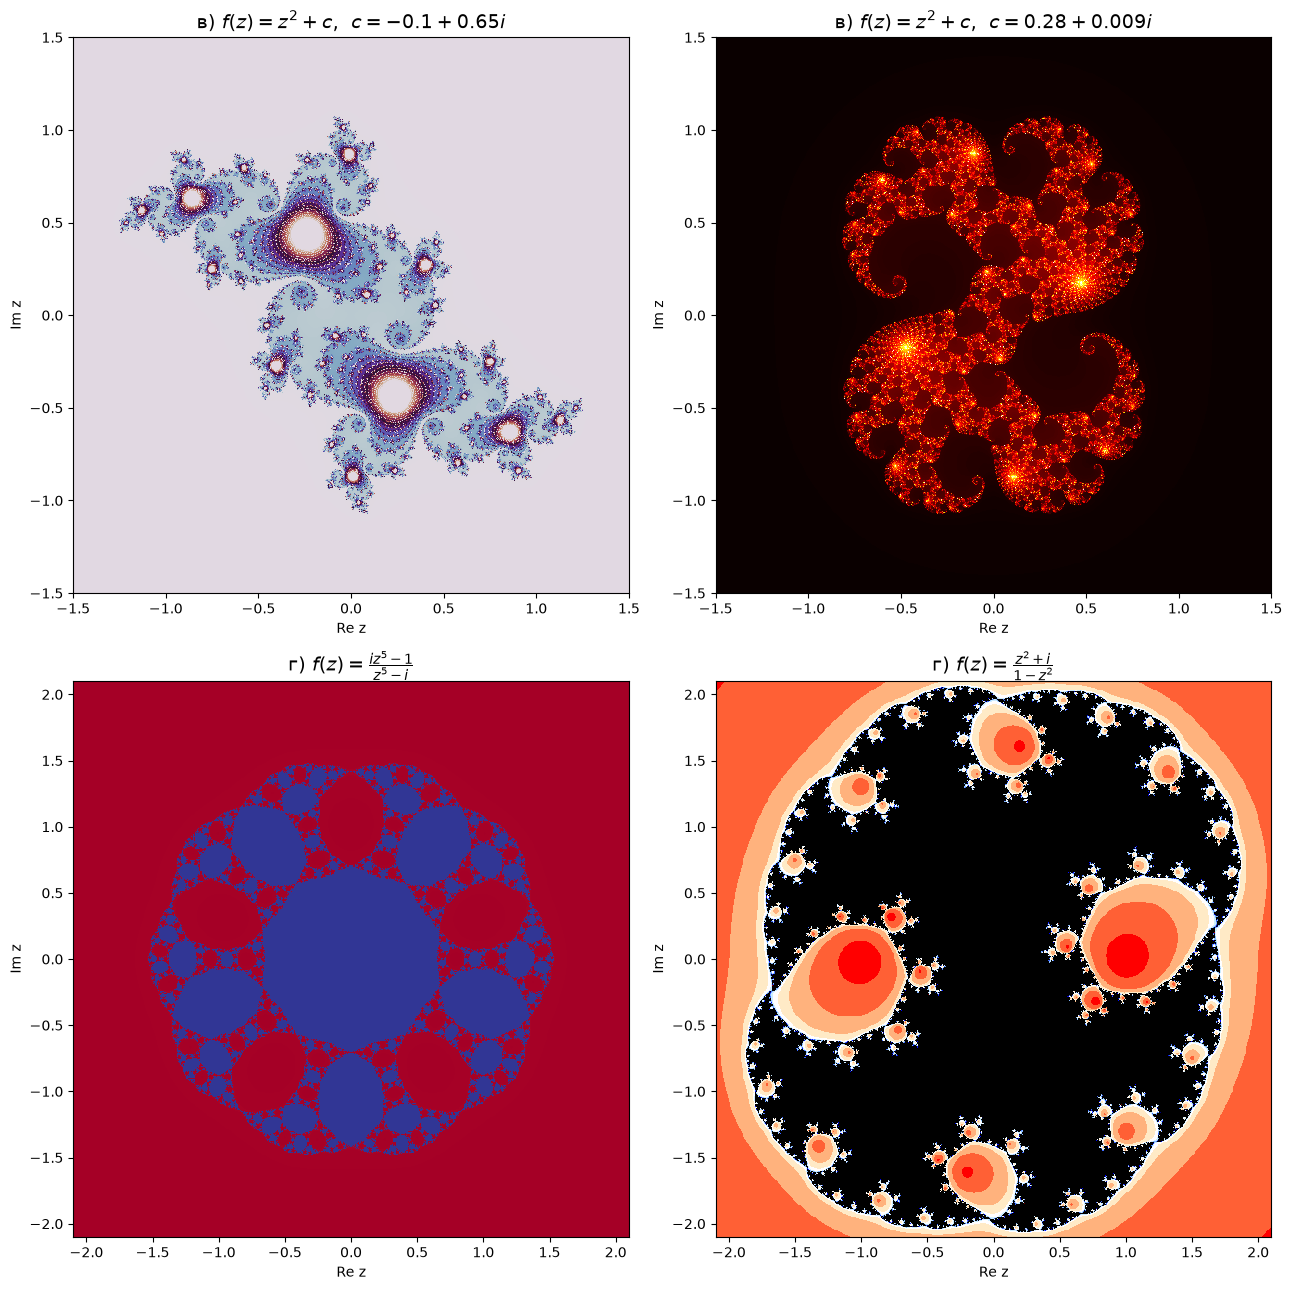

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def julia(f, n=600, lim=2.1, zabs_max=10, nit_max=1000):
    # Каждому пикселю сопоставляем точку квадрата [-lim, lim] × [-lim, lim]
    x = np.linspace(-lim, lim, n)
    X, Y = np.meshgrid(x, x)
    z = (X + 1j*Y).ravel()

    nit = np.zeros(z.size, dtype=int)
    idx = np.arange(z.size)                 # номера точек, которые ещё не «убежали»

    with np.errstate(all='ignore'):         # деление на 0 в полюсе даёт inf — такая точка считается убежавшей
        for _ in range(nit_max):
            z[idx] = f(z[idx])              # одна итерация сразу для всех активных точек
            nit[idx] += 1
            idx = idx[np.abs(z[idx]) <= zabs_max]   # оставляем только точки внутри круга |z| <= zabs_max
            if idx.size == 0:
                break

    return (nit / nit_max).reshape(n, n)


c1, c2 = complex(-0.1, 0.65), complex(0.28, 0.009)

# Связность J_c: проверяем, убегает ли орбита критической точки z = 0
for c in (c1, c2):
    z, n = 0j, 0
    while abs(z) <= 10 and n < 10**6:
        z, n = z*z + c, n + 1
    alpha = (1 - np.sqrt(1 - 4*c))/2            # неподвижная точка f_c
    print(f"c = {c}: орбита нуля " + (f"убегает на шаге {n} -> J_c несвязно («пыль»)" if abs(z) > 10
                                         else "ограничена -> J_c связно") + f";  |f'(alpha)| = {abs(2*alpha):.4f}")
print()

# (название, заголовок рисунка, отображение, цветовая карта, размер окна, максимальное число итераций)
maps = [
    ("в) z^2 + c, c = -0.1 + 0.65i", r"в) $f(z)=z^2+c$,  $c=-0.1+0.65i$", lambda z: z**2 + c1, 'twilight', 1.5, 1000),
    ("в) z^2 + c, c = 0.28 + 0.009i", r"в) $f(z)=z^2+c$,  $c=0.28+0.009i$", lambda z: z**2 + c2, 'hot', 1.5, 400),
    ("г) (i z^5 - 1)/(z^5 - i)", r"г) $f(z)=\frac{iz^5-1}{z^5-i}$", lambda z: (1j*z**5 - 1)/(z**5 - 1j), 'RdYlBu', 2.1, 1000),
    ("г) (z^2 + i)/(1 - z^2)", r"г) $f(z)=\frac{z^2+i}{1-z^2}$", lambda z: (z*z + 1j)/(1 - z*z), 'flag', 2.1, 1000),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 13))

for ax, (name, title, f, cmap, lim, nit_max) in zip(axes.flat, maps):
    ratio = julia(f, lim=lim, nit_max=nit_max)
    print(f"{name}: доля точек, не убежавших за {nit_max} итераций = {np.mean(ratio == 1):.3f}")

    # origin='lower': мнимая ось направлена вверх
    ax.imshow(ratio, cmap=cmap, extent=[-lim, lim, -lim, lim], origin='lower', interpolation='nearest')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Re z")
    ax.set_ylabel("Im z")

plt.tight_layout()
plt.show()